## Setup

In [ ]:
from pathlib import Path
import sys,os,json
import numpy as np

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "config.py").is_file()
)
sys.path.insert(0, str(project_root))

from src.config import valid_ext, image_size, data_dir, seed,set_seed
from src.data_loader import clean_dataset, load_dataset
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical, plot_model
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

set_seed()

2026-10-15 15:14:45.015786: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
X, y, classes = load_dataset(data_dir)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## Shape

In [3]:
print(X.shape, classes)

(7023, 224, 224, 3) ['glioma', 'meningioma', 'notumor', 'pituitary']


## Explore the data

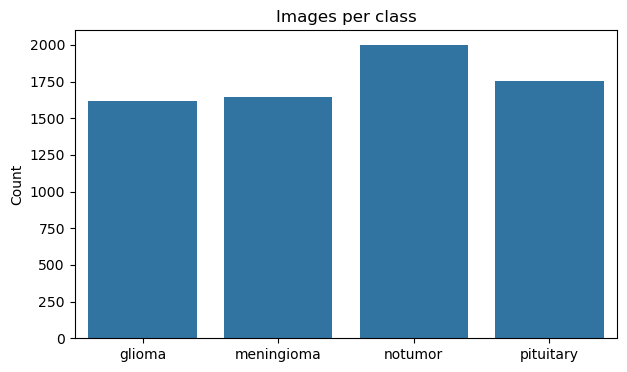

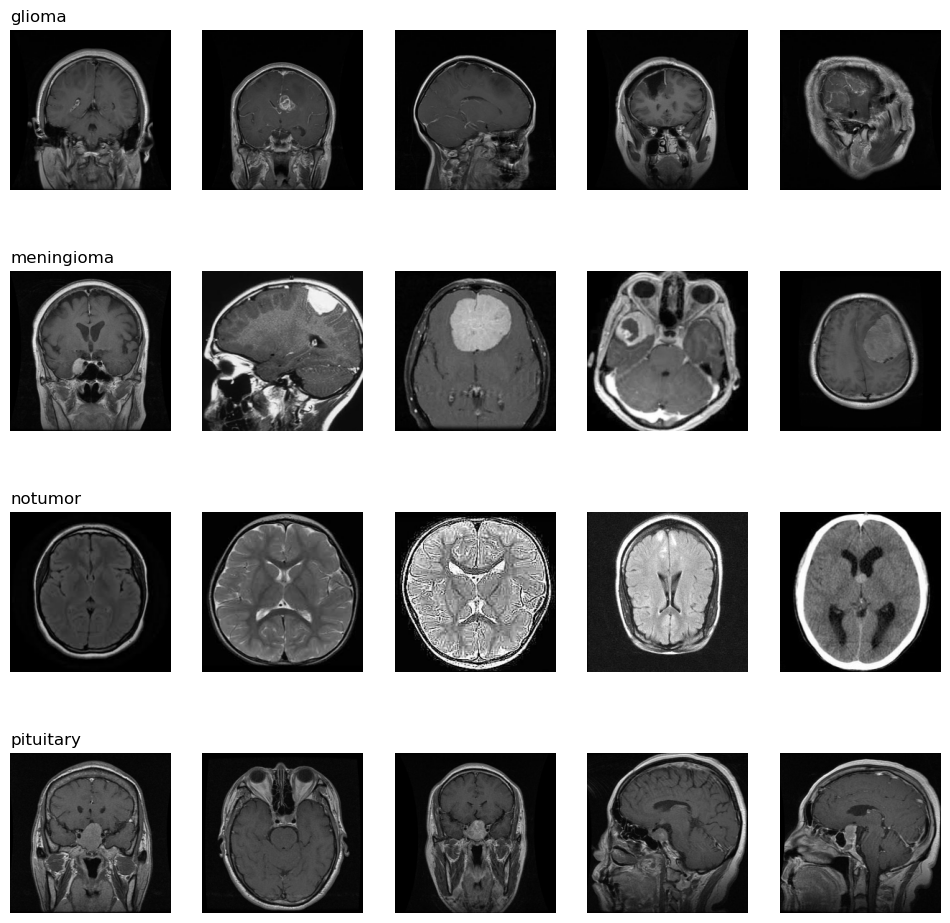

In [4]:
unique, counts = np.unique(y, return_counts=True)
plt.figure(figsize=(7,4))
sns.barplot(x=unique, y=counts)
plt.title("Images per class"); plt.ylabel("Count")
plt.show()


fig, axes = plt.subplots(len(classes), 5, figsize=(12, 3*len(classes)))
for i, cls in enumerate(classes):
    idx = np.where(y == cls)[0][:5]
    for j, k in enumerate(idx):
        axes[i, j].imshow(X[k]); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(cls, loc="left")
plt.show()

In [ ]:
le = LabelEncoder()

y_int = le.fit_transform(y)
y_cat = to_categorical(y_int)

os.makedirs("models", exist_ok=True)
json.dump(list(le.classes_), open("models/classes.json", "w"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat, test_size=0.2, stratify=y_int, random_state=seed
)

## Normalize

In [ ]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0